In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\HP\Downloads\ab_test_data.csv")

print(df.shape)
df.head()

(6000, 11)


,user_id,group,user_type,feature_seen,feature_clicked,feature_used,retained_day7,purchase,signup_date,device,region
0,100001,Treatment,New,1,0,0,0,1,2026-07-12,Desktop,North America
1,100002,Control,Returning,1,0,0,1,0,2026-07-09,Tablet,North America
2,100003,Treatment,New,1,1,1,1,0,2026-07-03,Mobile,North America
3,100004,Control,New,0,0,0,0,0,2026-07-21,Mobile,Other
4,100005,Control,New,1,0,0,1,0,2026-07-05,Mobile,Europe


In [4]:
df.isnull().sum()

user_id            0
group              0
user_type          0
feature_seen       0
feature_clicked    0
feature_used       0
retained_day7      0
purchase           0
signup_date        0
device             0
region             0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df["user_id"].duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   user_id          6000 non-null   int64
 1   group            6000 non-null   str  
 2   user_type        6000 non-null   str  
 3   feature_seen     6000 non-null   int64
 4   feature_clicked  6000 non-null   int64
 5   feature_used     6000 non-null   int64
 6   retained_day7    6000 non-null   int64
 7   purchase         6000 non-null   int64
 8   signup_date      6000 non-null   str  
 9   device           6000 non-null   str  
 10  region           6000 non-null   str  
dtypes: int64(6), str(5)
memory usage: 744.6 KB


In [8]:
df["signup_date"] = pd.to_datetime(df["signup_date"])

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   user_id          6000 non-null   int64         
 1   group            6000 non-null   str           
 2   user_type        6000 non-null   str           
 3   feature_seen     6000 non-null   int64         
 4   feature_clicked  6000 non-null   int64         
 5   feature_used     6000 non-null   int64         
 6   retained_day7    6000 non-null   int64         
 7   purchase         6000 non-null   int64         
 8   signup_date      6000 non-null   datetime64[us]
 9   device           6000 non-null   str           
 10  region           6000 non-null   str           
dtypes: datetime64[us](1), int64(6), str(4)
memory usage: 686.0 KB


In [10]:
df["group"].value_counts()

group
Treatment    3000
Control      3000
Name: count, dtype: int64

In [11]:
cols = ["feature_seen", "feature_clicked", "feature_used",
        "retained_day7", "purchase"]

for col in cols:
    print(col, df[col].unique())

feature_seen [1 0]
feature_clicked [0 1]
feature_used [0 1]
retained_day7 [0 1]
purchase [1 0]


In [12]:
print("Clicks without seeing feature:",
      ((df["feature_clicked"] == 1) & (df["feature_seen"] == 0)).sum())

print("Usage without clicking:",
      ((df["feature_used"] == 1) & (df["feature_clicked"] == 0)).sum())

Clicks without seeing feature: 0
Usage without clicking: 0


In [13]:
print(df["user_type"].value_counts())
print(df["device"].value_counts())
print(df["region"].value_counts())

user_type
New          4358
Returning    1642
Name: count, dtype: int64
device
Mobile     3664
Desktop    1834
Tablet      502
Name: count, dtype: int64
region
North America    2283
Europe           1578
Asia-Pacific     1539
Other             600
Name: count, dtype: int64


In [14]:
df.groupby("group")["retained_day7"].agg(["count", "sum", "mean"])

,count,sum,mean
group,,,
Control,3000,836,0.278667
Treatment,3000,991,0.330333


In [15]:
from statsmodels.stats.proportion import proportions_ztest

successes = [836, 991]
users = [3000, 3000]

z_stat, p_value = proportions_ztest(successes, users)

print("Z-statistic:", round(z_stat, 4))
print("P-value:", p_value)

Z-statistic: -4.3482
P-value: 1.3723218707548522e-05


In [16]:
from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    991, 3000,
    836, 3000,
    method="newcomb"
)

print("95% CI:", round(ci_low * 100, 2), "% to",
      round(ci_high * 100, 2), "%")

95% CI: 2.84 % to 7.49 %


In [17]:
control_rate = 836 / 3000
treatment_rate = 991 / 3000

absolute_lift = treatment_rate - control_rate
relative_lift = absolute_lift / control_rate

print("Control retention:", round(control_rate * 100, 2), "%")
print("Treatment retention:", round(treatment_rate * 100, 2), "%")
print("Absolute lift:", round(absolute_lift * 100, 2), "percentage points")
print("Relative lift:", round(relative_lift * 100, 2), "%")
print("Additional retained users:", 991 - 836)

Control retention: 27.87 %
Treatment retention: 33.03 %
Absolute lift: 5.17 percentage points
Relative lift: 18.54 %
Additional retained users: 155


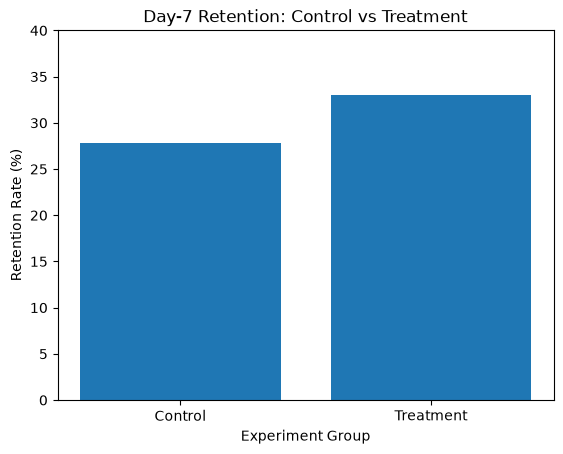

In [18]:
import matplotlib.pyplot as plt

groups = ["Control", "Treatment"]
retention_rates = [27.87, 33.03]

plt.bar(groups, retention_rates)
plt.title("Day-7 Retention: Control vs Treatment")
plt.ylabel("Retention Rate (%)")
plt.xlabel("Experiment Group")
plt.ylim(0, 40)

plt.show()

In [19]:
df.groupby("group")[["feature_clicked", "feature_used", "purchase"]].mean() * 100

,feature_clicked,feature_used,purchase
group,,,
Control,31.0,18.666667,9.766667
Treatment,32.1,21.066667,11.033333


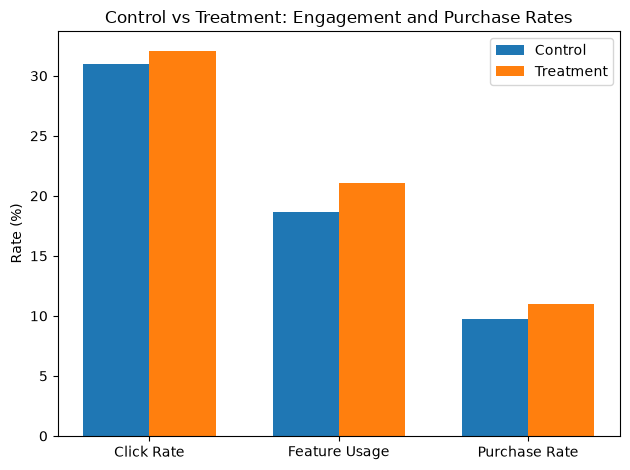

In [20]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Click Rate", "Feature Usage", "Purchase Rate"]
control = [31.00, 18.67, 9.77]
treatment = [32.10, 21.07, 11.03]

x = np.arange(len(metrics))
width = 0.35

plt.bar(x - width/2, control, width, label="Control")
plt.bar(x + width/2, treatment, width, label="Treatment")

plt.xticks(x, metrics)
plt.ylabel("Rate (%)")
plt.title("Control vs Treatment: Engagement and Purchase Rates")
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
from statsmodels.stats.proportion import proportions_ztest

control_purchases = df[df["group"] == "Control"]["purchase"].sum()
treatment_purchases = df[df["group"] == "Treatment"]["purchase"].sum()

successes = [control_purchases, treatment_purchases]
users = [3000, 3000]

z_stat, p_value = proportions_ztest(successes, users)

print("Control purchases:", control_purchases)
print("Treatment purchases:", treatment_purchases)
print("Z-statistic:", round(z_stat, 4))
print("P-value:", p_value)

Control purchases: 293
Treatment purchases: 331
Z-statistic: -1.6071
P-value: 0.10803698184884045


In [22]:
control_usage = df[df["group"] == "Control"]["feature_used"].sum()
treatment_usage = df[df["group"] == "Treatment"]["feature_used"].sum()

successes = [control_usage, treatment_usage]
users = [3000, 3000]

z_stat, p_value = proportions_ztest(successes, users)

print("Control feature usage:", control_usage)
print("Treatment feature usage:", treatment_usage)
print("Z-statistic:", round(z_stat, 4))
print("P-value:", p_value)

Control feature usage: 560
Treatment feature usage: 632
Z-statistic: -2.3296
P-value: 0.019825484145717567
